# LVDB + star formation rates: towards the Kennicutt–Schmidt plane

The Kennicutt–Schmidt (KS) relation links the star formation rate surface density $\Sigma_{\rm SFR}$
to the gas surface density $\Sigma_{\rm gas}$. To place Local Volume dwarfs on it we need, per galaxy,
a gas mass, a star formation rate (SFR), and one area to divide both by. No single catalogue has all
three, so this notebook consolidates three:

| folder | catalogue | what it supplies | source |
| --- | --- | --- | --- |
| `LVDB/` | Local Volume Database v1.1.1 (Pace et al.) | H I mass, stellar mass, half-light radius, distance, metallicity, groups | GitHub release `comb_all.csv` |
| `KK13/` | Karachentsev & Kaisina 2013, AJ 146, 46 | integrated SFR from H$\alpha$ and from GALEX FUV, with upper limits | CDS `J/AJ/146/46` |
| `UNGC/` | Updated Nearby Galaxy Catalog, Karachentsev et al. 2013, AJ 145, 101 | the distances KK13's SFRs were computed at, and the Holmberg diameter $A_{26}$ | CDS `J/AJ/145/101` |

KK13 is built on the UNGC (every KK13 galaxy is a UNGC row, joined by name), so the pair travels
together; LVDB is joined to them on sky position.

Each catalogue is a fixed published file, fetched once into its folder the same way `LVDB/comb_all.csv`
was taken from the LVDB release. `fetch()` below only downloads what is missing and never overwrites.

In [1]:
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.io import ascii
from utils.loading import ROOT                      # project root, so the path survives any cwd

ROOT = Path(ROOT)
SOURCES = {                                         # local file -> where it was downloaded from
    "LVDB/comb_all.csv": "https://github.com/apace7/local_volume_database/releases/download/v1.1.1/comb_all.csv",
    "KK13/ReadMe":       "https://cdsarc.cds.unistra.fr/ftp/J/AJ/146/46/ReadMe",
    "KK13/table3.dat":   "https://cdsarc.cds.unistra.fr/ftp/J/AJ/146/46/table3.dat",
    "UNGC/ReadMe":       "https://cdsarc.cds.unistra.fr/ftp/J/AJ/145/101/ReadMe",
    "UNGC/table1.dat":   "https://cdsarc.cds.unistra.fr/ftp/J/AJ/145/101/table1.dat",
    "UNGC/table2.dat":   "https://cdsarc.cds.unistra.fr/ftp/J/AJ/145/101/table2.dat",
}


def fetch(sources=SOURCES, root=ROOT):
    # Download each catalogue file that is not already on disk. Existing files are left alone.
    for rel, url in sources.items():
        path = root / rel
        if path.exists():
            continue
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f"downloading {rel} <- {url}")
        urllib.request.urlretrieve(url, path)


fetch()
for rel in SOURCES:
    print(f"{rel:20s} {(ROOT / rel).stat().st_size / 1e3:8.1f} kB")

LVDB/comb_all.csv       835.1 kB
KK13/ReadMe               6.8 kB
KK13/table3.dat          71.1 kB
UNGC/ReadMe              23.2 kB
UNGC/table1.dat         107.6 kB
UNGC/table2.dat         108.0 kB


## 1. LVDB

`LVDB/comb_all.csv` is the whole LVDB in one file: one row per object (dwarf galaxies, globular
clusters, and UNCONFIRMED candidates). Data is aggregated from other papers using the reference. A
blank cell means the quantity was never measured.

### Three naming conventions carry the file

- **`<quantity>_em` / `_ep`** — the 1σ error below and above the value, both quoted positive.
  `<quantity>` alone is the value.
- **`<quantity>_ul`** — the same quantity as an **upper limit** rather than a value: the limit sits in the
  `_ul` column and `<quantity>` is left blank. 130 objects carry their H I mass this way (`mass_HI_ul`),
  so read `<quantity>` or `<quantity>_ul`, whichever is filled.
- **`ref_<quantity>`** — the source paper, as an ADS bibcode (`Karachentsev2013AJ....145..101K`).
- **`table`** — which LVDB table the row came from: dwarf satellites of the Milky Way or M31, Local Field
  dwarfs (near and distant), globular clusters, and unconfirmed `candidate`s.

In [2]:
df = pd.read_csv(ROOT / "LVDB" / "comb_all.csv").copy()   # .copy() defragments the 122-column frame
print(f"{len(df):,} objects x {df.shape[1]} columns")
base = [c for c in df.columns if not c.startswith("ref_") and not c.endswith(("_em", "_ep", "_ul"))]
refs = [c for c in df.columns if c.startswith("ref_")]
print(f"{len(base)} quantities, {len(refs)} with a source paper, "
      f"{sum(1 for c in base if c + '_ep' in df.columns)} with a quoted error")
print()
print(df["table"].value_counts().to_string())

1,727 objects x 122 columns
51 quantities, 12 with a source paper, 26 with a quoted error

table
dwarf_local_field_distant    736
gc_dwarf_hosted              313
candidate                    214
gc_harris                    155
dwarf_mw                      68
dwarf_local_field             64
gc_mw_new                     58
misc                          47
dwarf_m31                     43
gc_ambiguous                  22
gc_other                       7


### What the columns are

| group | columns | unit |
| --- | --- | --- |
| identity | `key`, `name`, `host`, `table`, `confirmed_real`, `confirmed_galaxy` | — |
| sky position | `ra`, `dec`, `ll`, `bb`, `sg_xx`, `sg_yy`, `sg_zz` | deg; kpc |
| distance | `distance`, `distance_modulus`, `distance_gc`, `distance_m31`, `distance_lg`, `distance_host`, `distance_measurement_method` | kpc; mag |
| light | `apparent_magnitude_v`, `M_V`, `surface_brightness_rhalf` | mag; mag arcsec⁻² |
| mass | `mass_stellar`, `mass_HI`, `mass_dynamical_wolf`, `flux_HI` | log₁₀ M☉; Jy km s⁻¹ |
| structure | `rhalf`, `rhalf_physical`, `rhalf_sph_physical`, `ellipticity`, `position_angle`, `rcore`, `rking`, `rad_sersic`, `n_sersic` | arcmin; pc; deg |
| motion | `vlos_systemic`, `vlos_sigma`, `velocity_gsr`, `velocity_lg`, `pmra`, `pmdec` | km s⁻¹; mas yr⁻¹ |
| chemistry | `metallicity`, `metallicity_spectroscopic`, `metallicity_isochrone`, `metallicity_photometric`, `age` | [Fe/H] dex; Gyr |

`ra`/`dec` are ICRS; `ll`/`bb` are Galactic longitude and latitude (astropy `SkyCoord(...).galactic`
reproduces them to 1e-7 deg); `sg_xx`, `sg_yy`, `sg_zz` are the Sun-centred supergalactic position, whose
length equals `distance`. `distance_gc`, `distance_m31`, `distance_lg` and `distance_host` are distances
from the Galactic centre, M31, the Local Group, and the row's host galaxy.

Units are read off the data, not from the column names: against the LMC, SMC and NGC 6822, `mass_stellar`
and `mass_HI` come out as log₁₀ M☉, and `rhalf_physical` equals `distance` × `rhalf` for every row.

**LVDB has no star formation rate and no H I radius.** Those are what the next two catalogues add.

In [3]:
df[df["key"] == "smc"].T                            # one row, read down the page

,55
key,smc
ra,16.25
dec,-72.42
name,SMC
host,lmc
...,...
rhalf_sph_physical_ep,92.78
surface_brightness_rhalf,21.95
distance_measurement_method,NaN
table,dwarf_mw


## 2. KK13 and the UNGC

Both are CDS fixed-width tables, read with their own `ReadMe` (astropy's `cds` reader), so names,
units and blank values come from the catalogue's own description.

**KK13 `table3`** (802 galaxies within 11 Mpc). `SFRa` and `SFRu` are log₁₀ SFR [M☉ yr⁻¹] from H$\alpha$
(KK13 eq. 1, following Kennicutt 1998) and from FUV (KK13 eq. 3, following Lee et al. 2011), both
corrected for Galactic and internal extinction. `l_SFRa` / `l_SFRu` = `<` marks an upper limit.
The two tracers see different ages: H$\alpha$ traces O stars with ages ≲5 Myr (sensitive out to ~10 Myr),
FUV traces O and B stars of typical age 20–30 Myr (sensitive out to ~100 Myr) (Schruba et al. 2011, p.3).

**UNGC `table1` / `table2`** (869 galaxies). `Dist` [Mpc] is the distance KK13's SFRs were computed at.
`A26` [kpc] is the linear diameter at the Holmberg isophote (~26.5 mag arcsec⁻² in B), already corrected
for Galactic extinction and inclination. `MHI` is log₁₀ hydrogen mass.

In [4]:
def read_cds(folder, table):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ascii.read(ROOT / folder / table, readme=ROOT / folder / "ReadMe", format="cds").to_pandas()


def cds_coords(t):
    sign = np.where(t["DE-"] == "-", -1.0, 1.0)
    ra = 15.0 * (t["RAh"] + t["RAm"] / 60 + t["RAs"] / 3600)
    dec = sign * (t["DEd"] + t["DEm"] / 60 + t["DEs"] / 3600)
    return ra, dec


kk = read_cds("KK13", "table3.dat")
ungc1 = read_cds("UNGC", "table1.dat")
ungc2 = read_cds("UNGC", "table2.dat")
assert (ungc1["Name"].values == ungc2["Name"].values).all()    # same rows, same order
print(f"KK13 {len(kk)} galaxies; UNGC {len(ungc1)}; KK13 names found in UNGC: {kk['Name'].isin(ungc1['Name']).sum()}")

ungc = ungc1[["Name", "Dist", "a26", "b/a", "Mcl"]].join(ungc2[["A26", "i", "MHI", "l_MHI", "KLum"]])
sfr = kk.merge(ungc, on="Name", how="left", validate="1:1")
sfr["ra"], sfr["dec"] = cds_coords(sfr)
sfr = pd.DataFrame({
    "kk_name": sfr["Name"], "kk_ra": sfr["ra"], "kk_dec": sfr["dec"], "TT": sfr["TT"], "Mcl": sfr["Mcl"],
    "log_sfr_ha": sfr["SFRa"], "sfr_ha_ul": sfr["l_SFRa"] == "<",
    "log_sfr_fuv": sfr["SFRu"], "sfr_fuv_ul": sfr["l_SFRu"] == "<",
    "dist_ungc_kpc": 1e3 * sfr["Dist"], "A26_kpc": sfr["A26"], "log_mhi_ungc": sfr["MHI"],
})
print(f"with an Halpha SFR: {sfr['log_sfr_ha'].notna().sum()} ({sfr['sfr_ha_ul'].sum()} limits); "
      f"with an FUV SFR: {sfr['log_sfr_fuv'].notna().sum()} ({sfr['sfr_fuv_ul'].sum()} limits)")
sfr.head()

KK13 802 galaxies; UNGC 869; KK13 names found in UNGC: 802
with an Halpha SFR: 500 (41 limits); with an FUV SFR: 717 (98 limits)


,kk_name,kk_ra,kk_dec,TT,Mcl,log_sfr_ha,sfr_ha_ul,log_sfr_fuv,sfr_fuv_ul,dist_ungc_kpc,A26_kpc,log_mhi_ungc
0,UGC12894,0.093750,39.495556,10,Ir,-2.48,False,-2.03,False,8470.0,2.78,7.92
1,WLM,0.492083,-15.461111,9,Im,-2.69,False,-2.24,False,970.0,3.21,7.83
2,And XVIII,0.560417,45.088889,-3,Sph,NaN,False,-5.81,True,1360.0,0.63,NaN
3,ESO409-015,1.382500,-28.098056,9,Im,-1.57,False,-1.82,False,7700.0,2.65,7.99
4,AGC748778,1.643333,15.510833,10,Ir,NaN,False,-3.65,False,5400.0,0.53,6.51


## 3. Consolidating: LVDB × KK13/UNGC

**Matching.** LVDB rows (dwarfs and `misc`; clusters and candidates left out) are matched to the nearest
KK13 galaxy on the sky. The tolerance is 1′, or 1.2 × the LVDB half-light radius when that is larger:
the catalogue centres of big, diffuse systems (LMC, SMC, Boötes III) differ by up to ~1°. If two LVDB
rows land on the same KK13 galaxy, the closer one is kept. The matches beyond 5′ are printed so they can
be checked by name.

**Distances.** KK13's SFRs and the UNGC's $A_{26}$ are at UNGC distances; LVDB's H I masses are at LVDB
distances. A flux-derived SFR scales as $D^2$ and a linear size as $D$, so both are rescaled to the LVDB
distance before anything is combined:
$\log {\rm SFR} \to \log {\rm SFR} + 2\log(D_{\rm LVDB}/D_{\rm UNGC})$, $A_{26} \to A_{26}\,D_{\rm LVDB}/D_{\rm UNGC}$.

In [5]:
KEEP = ["dwarf_mw", "dwarf_m31", "dwarf_local_field", "dwarf_local_field_distant", "misc"]
MATCH_ARCMIN = 1.0

gal = df[df["table"].isin(KEEP)].copy()
lv_c = SkyCoord(gal["ra"].values * u.deg, gal["dec"].values * u.deg)
kk_c = SkyCoord(sfr["kk_ra"].values * u.deg, sfr["kk_dec"].values * u.deg)
idx, sep, _ = lv_c.match_to_catalog_sky(kk_c)
gal["sep_arcmin"] = sep.arcmin
tol = np.maximum(MATCH_ARCMIN, 1.2 * gal["rhalf"].fillna(0))
hit = gal["sep_arcmin"] < tol
gal["kk_idx"] = np.where(hit, idx, -1)
closest_first = gal[hit].sort_values("sep_arcmin")
gal.loc[closest_first.index[closest_first.duplicated("kk_idx")], "kk_idx"] = -1   # one LVDB row per KK13 galaxy
gal = gal.join(sfr, on="kk_idx")                                                  # -1 joins to nothing
for c in ("sfr_ha_ul", "sfr_fuv_ul"):
    gal[c] = gal[c].eq(True)

# rescale to the LVDB distance
dlog = np.log10(gal["distance"] / gal["dist_ungc_kpc"])
gal["log_sfr_ha"] += 2 * dlog
gal["log_sfr_fuv"] += 2 * dlog
gal["R26_kpc"] = 0.5 * gal["A26_kpc"] * 10**dlog

m = gal["kk_name"].notna()
print(f"LVDB galaxies kept: {len(gal)}; matched to KK13: {m.sum()}")
print(f"separations of matches: median {gal.loc[m, 'sep_arcmin'].median():.2f}', "
      f"95th percentile {gal.loc[m, 'sep_arcmin'].quantile(0.95):.2f}'")
print(f"distance rescaling |2 log(D_LVDB/D_UNGC)|: median {2 * dlog[m].abs().median():.3f} dex, "
      f"max {2 * dlog[m].abs().max():.2f} dex ({gal.loc[dlog[m].abs().idxmax(), 'name']})")
print("\nmatches beyond 5' (check the names agree):")
print(gal.loc[m & (gal["sep_arcmin"] > 5), ["key", "kk_name", "sep_arcmin", "rhalf"]].round(1).to_string(index=False))

LVDB galaxies kept: 958; matched to KK13: 455
separations of matches: median 0.00', 95th percentile 0.59'
distance rescaling |2 log(D_LVDB/D_UNGC)|: median 0.039 dex, max 0.75 dex (UGC 8245)

matches beyond 5' (check the names agree):
     key   kk_name  sep_arcmin  rhalf
bootes_3 BootesIII        19.9   40.6
     lmc       LMC        56.3  192.9
     smc       SMC        59.9   59.4


In [6]:
# the consolidated table, one row per LVDB galaxy, written next to this notebook
COLS = ["key", "name", "table", "ra", "dec", "distance", "mass_stellar", "mass_HI", "mass_HI_ul",
        "rhalf_physical", "metallicity", "kk_name", "sep_arcmin", "dist_ungc_kpc", "TT", "Mcl",
        "log_sfr_ha", "sfr_ha_ul", "log_sfr_fuv", "sfr_fuv_ul", "R26_kpc", "log_mhi_ungc"]
gal[COLS].to_csv("lvdb_kk13_ungc.csv", index=False)
print(f"wrote lvdb_kk13_ungc.csv: {len(gal)} rows, {m.sum()} with KK13/UNGC data")

wrote lvdb_kk13_ungc.csv: 958 rows, 455 with KK13/UNGC data


## 4. Scaling relations

Here we can use the data to plot observational scaling relations seen within the local group. We are
principally interested in chemical compositions of dwarf galaxies, however exploring others will allow
us to further narrow the domain we are similar to when compared to observations.

`mass_stellar` and `mass_HI` are already log₁₀ M☉, so they go on a linear axis; only quantities stored
linearly (radii, distances) get a log axis.

In [7]:
GROUPS = {"dwarf_mw": "Milky Way dwarf", "dwarf_m31": "M31 dwarf",
          "dwarf_local_field": "Local Field dwarf", "dwarf_local_field_distant": "Local Field dwarf",
          "gc_mw_new": "globular cluster", "gc_harris": "globular cluster",
          "gc_dwarf_hosted": "globular cluster", "gc_ambiguous": "globular cluster",
          "gc_other": "globular cluster",
          "candidate": "candidate", "misc": "misc"}
COLOUR = {"Milky Way dwarf": "#0072B2", "M31 dwarf": "#E69F00", "Local Field dwarf": "#009E73",
          "globular cluster": "#CC79A7", "candidate": "#999999", "misc": "#000000"}
LABEL = {"lmc": (20, 0), "smc": (-12, 16), "leo_p": (4, -28)}   # offsets in points
LOG_STORED = {"mass_stellar", "mass_HI", "mass_dynamical_wolf", "log_mHI_mstar", "log_sfr_ha", "log_sfr_fuv"}
AXIS = {"rhalf": "half-light radius [arcmin]", "rhalf_physical": "half-light radius [pc]",
        "rhalf_sph_physical": "half-light radius, spherical [pc]",
        "M_V": "absolute V magnitude [mag]", "apparent_magnitude_v": "apparent V magnitude [mag]",
        "mass_stellar": r"stellar mass [log$_{10}$ M$_\odot$]", "mass_HI": r"H I mass [log$_{10}$ M$_\odot$]",
        "log_mHI_mstar": r"$\log_{10}(M_{\rm HI}/M_\star)$",
        "metallicity": "metallicity [Fe/H]", "distance": "distance from the Sun [kpc]",
        "vlos_systemic": "systemic velocity [km s$^{-1}$]"}
df["group"] = df["table"].map(GROUPS)
gal["group"] = gal["table"].map(GROUPS)
assert df["group"].notna().all(), "a `table` value is missing from GROUPS"


def plot_pair(x_key, y_key, data=None, target=None, log_x=None, invert_y=False, labels=LABEL, ax=None):
    # Scatter two columns against each other, coloured by object group.
    #   x_key, y_key : column names, e.g. "rhalf_physical" and "M_V".
    #   data         : the dataset to plot; defaults to the LVDB frame `df`.
    #   target       : drawn on top as white diamonds -- a frame with both keys, or a dict
    #                  {key: value} for one object, such as a simulated galaxy.
    #   log_x        : logarithmic x axis; by default only for columns not already stored as log10.
    #   invert_y     : flip the y axis (for magnitudes, so brighter is up).
    #   labels       : offsets in points for named objects, keyed by `key`; {} switches them off.
    src = (df if data is None else data).dropna(subset=[x_key, y_key])
    print(f"{len(src):,} rows with both {x_key} and {y_key}")
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))
    for group, colour in COLOUR.items():
        s = src[src["group"] == group]
        if len(s):
            ax.scatter(s[x_key], s[y_key], s=6, c=colour, label=f"{group} ({len(s)})")
    for key, offset in labels.items():
        hit = src[src["key"] == key]
        if hit.empty:
            continue
        row = hit.iloc[0]
        ax.scatter(row[x_key], row[y_key], marker="*", s=170, c="white", edgecolors="black", linewidths=1.0, zorder=5)
        ax.annotate(row["name"], (row[x_key], row[y_key]), textcoords="offset points",
                    xytext=offset, ha="left", va="center", fontsize=9, zorder=6)
    if target is not None:
        tgt = pd.DataFrame(target, index=[0]) if isinstance(target, dict) else target
        ax.scatter(tgt[x_key], tgt[y_key], marker="D", s=70, c="white", edgecolors="crimson",
                   linewidths=1.4, zorder=7, label="target")
    if log_x if log_x is not None else x_key not in LOG_STORED:
        ax.set_xscale("log")
    if invert_y:
        ax.invert_yaxis()
    ax.set_xlabel(AXIS.get(x_key, x_key))
    ax.set_ylabel(AXIS.get(y_key, y_key))
    ax.legend(loc="best", fontsize=8, frameon=False)
    return ax.figure, ax

1,237 rows with both rhalf_physical and mass_stellar
341 rows with both mass_HI and mass_stellar


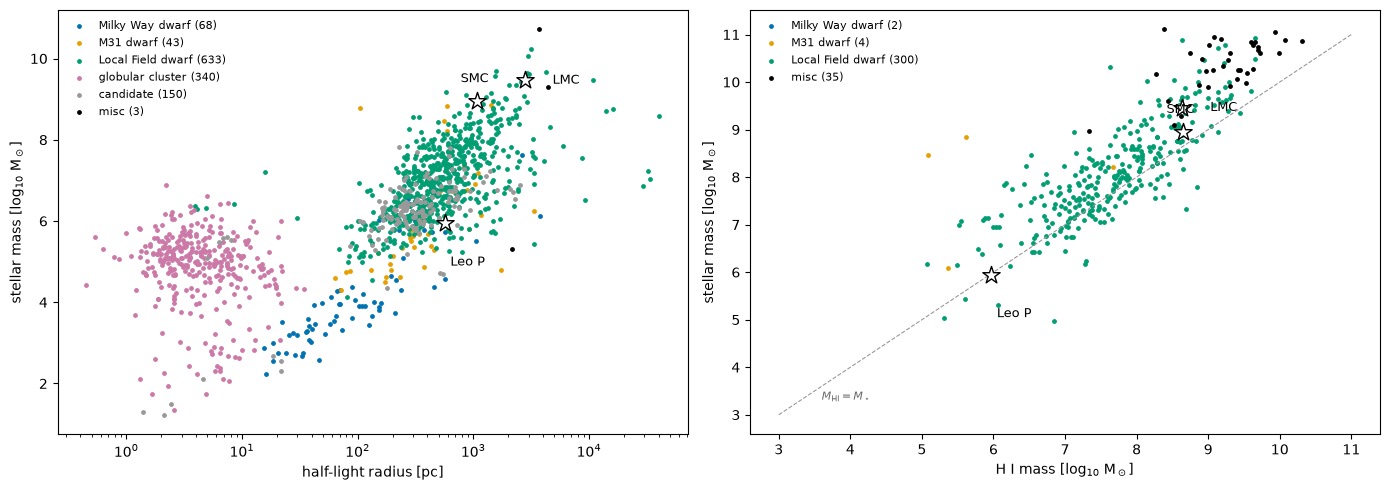

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_pair("rhalf_physical", "mass_stellar", ax=axes[0])
plot_pair("mass_HI", "mass_stellar", ax=axes[1])
axes[1].plot([3, 11], [3, 11], c="0.6", lw=0.8, ls="--")
axes[1].text(3.6, 3.3, r"$M_{\rm HI}=M_\star$", color="0.4", fontsize=8)
fig.tight_layout()
plt.show()

The gas fraction has to be a difference of logs, $\log_{10}(M_{\rm HI}/M_\star) = $ `mass_HI − mass_stellar`
(dividing the two log columns gives a number with no physical meaning).

18 rows with both log_mHI_mstar and metallicity


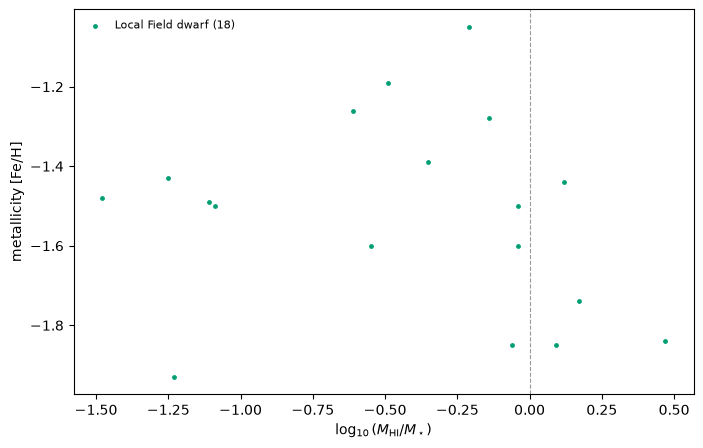

In [9]:
df["log_mHI_mstar"] = df["mass_HI"] - df["mass_stellar"]
fig, ax = plot_pair("log_mHI_mstar", "metallicity")
ax.axvline(0, c="0.6", lw=0.8, ls="--")
plt.show()

## 5. The Kennicutt–Schmidt plane

$$\Sigma_{\rm HI} = \frac{M_{\rm HI}}{\pi R^2}, \qquad \Sigma_{\rm SFR} = \frac{\rm SFR}{\pi R^2}$$

**Choices, stated so they can be changed:**

- **Aperture $R$ = Holmberg radius $R_{26} = A_{26}/2$** (UNGC, face-on, rescaled to the LVDB distance). This
  is the closest available analogue of Kennicutt (1998), who averaged H I within the optical radius, the
  RC2 corrected isophotal radius (Kennicutt 1998, p.4). The Holmberg isophote (26.5 mag arcsec⁻²) is
  fainter than the RC2 isophote (25 mag arcsec⁻² [unverified: not stated in the corpus]), so $R_{26}$ is larger and both surface densities come out lower.
  Both axes use the same area, so changing $R$ slides each point along a line of slope 1 (arrow on the plot).
- **Gas = H I only, hydrogen only**, as Bigiel et al. (2008, p.5 of the arXiv version) quote surface densities; their
  constant-depletion-time lines include helium (×1.36), and so do ours. H$_2$ is not included, so each
  $\Sigma_{\rm HI}$ is a lower limit on the total gas.
- **Total masses in a finite aperture.** LVDB's $M_{\rm HI}$ is the whole H I, which in the more massive dIrrs extends
  far beyond even the oldest stars (Tillaboev et al. 2025, p.5); dividing it by $\pi R_{26}^2$ is not the mean H I *within* $R_{26}$ that Kennicutt (1998)
  used.
- **Reference line:** Kennicutt (1998, eq. 4, p.15), $\Sigma_{\rm SFR} = (2.5\pm0.7)\times10^{-4}\,
  \Sigma_{\rm gas}^{1.4\pm0.15}$ [M☉ yr⁻¹ kpc⁻², M☉ pc⁻²].

Upper limits: an SFR limit is an open symbol with a downward arrow; an H I limit has a leftward arrow.

on the KS plane: 292 with FUV, 249 with Halpha


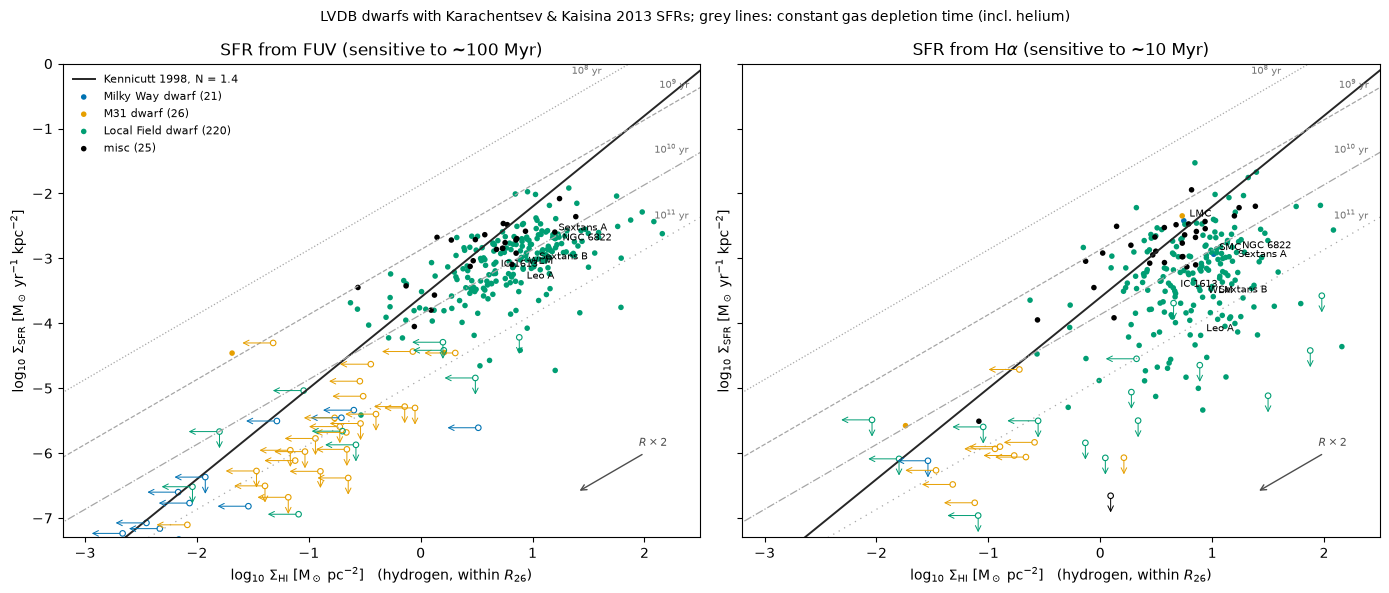

In [10]:
HELIUM = 1.36                           # Bigiel et al. 2008: x1.36 turns hydrogen into total gas
NAMED = ["lmc", "smc", "ngc_6822", "wlm", "ic_1613", "sextans_a", "sextans_b", "leo_a"]

gal["log_mhi"] = gal["mass_HI"].fillna(gal["mass_HI_ul"])
gal["hi_ul"] = gal["mass_HI"].isna() & gal["mass_HI_ul"].notna()
area_kpc2 = np.pi * gal["R26_kpc"] ** 2
gal["log_sig_hi"] = gal["log_mhi"] - np.log10(area_kpc2 * 1e6)            # Msun pc^-2
for tr in ("ha", "fuv"):
    gal[f"log_sig_sfr_{tr}"] = gal[f"log_sfr_{tr}"] - np.log10(area_kpc2)   # Msun yr^-1 kpc^-2
    gal[f"log_tdep_{tr}"] = np.log10(HELIUM) + gal["log_mhi"] - gal[f"log_sfr_{tr}"]   # yr

ks = gal.dropna(subset=["log_sig_hi"])
print(f"on the KS plane: {ks['log_sig_sfr_fuv'].notna().sum()} with FUV, {ks['log_sig_sfr_ha'].notna().sum()} with Halpha")


def draw_limits(ax, d, x, y, x_ul, y_ul, colour, dx=-0.3, dy=-0.3):
    # Open symbols for any limit; an arrow along each axis that is a limit.
    lim = d[d[x_ul] | d[y_ul]]
    ax.scatter(lim[x], lim[y], s=16, facecolors="none", edgecolors=colour, lw=0.8)
    for _, r in lim.iterrows():
        for is_ul, (ex, ey) in ((r[x_ul], (dx, 0)), (r[y_ul], (0, dy))):
            if is_ul:
                ax.annotate("", (r[x] + ex, r[y] + ey), (r[x], r[y]),
                            arrowprops=dict(arrowstyle="->", color=colour, lw=0.7))


def ks_panel(ax, tracer, title):
    y, y_ul = f"log_sig_sfr_{tracer}", f"sfr_{tracer}_ul"
    d = ks.dropna(subset=[y])
    x = np.linspace(-4, 3, 50)
    ax.plot(x, np.log10(2.5e-4) + 1.4 * x, c="0.15", lw=1.4, label="Kennicutt 1998, N = 1.4")
    for t, ls in ((1e8, ":"), (1e9, "--"), (1e10, "-."), (1e11, (0, (1, 4)))):
        yy = np.log10(HELIUM) + x + 6 - np.log10(t)                        # Sigma_SFR = 1.36 Sigma_HI / t
        ax.plot(x, yy, c="0.65", lw=0.9, ls=ls)
        xl = min(2.4, -0.25 - np.log10(HELIUM) - 6 + np.log10(t))           # stay below the top edge
        ax.text(xl, np.log10(HELIUM) + xl + 6 - np.log10(t) + 0.08, rf"$10^{{{int(np.log10(t))}}}$ yr",
                fontsize=7, color="0.45", ha="right")
    for g, col in COLOUR.items():
        s = d[d["group"] == g]
        if s.empty:
            continue
        det = s[~s[y_ul] & ~s["hi_ul"]]
        ax.scatter(det["log_sig_hi"], det[y], s=16, c=col, edgecolors="none", label=f"{g} ({len(s)})")
        draw_limits(ax, s, "log_sig_hi", y, "hi_ul", y_ul, col)
    for k in NAMED:
        r = d[d["key"] == k]
        if len(r):
            ax.annotate(r.iloc[0]["name"], (r.iloc[0]["log_sig_hi"], r.iloc[0][y]), xytext=(4, 3),
                        textcoords="offset points", fontsize=7)
    ax.annotate("", (2.0 - np.log10(4), -6.0 - np.log10(4)), (2.0, -6.0), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.text(1.95, -5.85, r"$R\times2$", fontsize=8, color="0.3", va="center")
    ax.set(xlim=(-3.2, 2.5), ylim=(-7.3, 0.0), title=title,
           xlabel=r"$\log_{10}\,\Sigma_{\rm HI}$ [M$_\odot$ pc$^{-2}$]   (hydrogen, within $R_{26}$)",
           ylabel=r"$\log_{10}\,\Sigma_{\rm SFR}$ [M$_\odot$ yr$^{-1}$ kpc$^{-2}$]")


fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
ks_panel(axes[0], "fuv", "SFR from FUV (sensitive to ~100 Myr)")
ks_panel(axes[1], "ha", r"SFR from H$\alpha$ (sensitive to ~10 Myr)")
axes[0].legend(fontsize=8, loc="upper left", frameon=False)
fig.suptitle("LVDB dwarfs with Karachentsev & Kaisina 2013 SFRs; grey lines: constant gas depletion time "
             "(incl. helium)", fontsize=10)
fig.tight_layout()
plt.show()

## 6. Aperture-free versions

The aperture cancels in the ratio of the two axes, so the depletion time
$\tau_{\rm dep} = 1.36\,M_{\rm HI}/{\rm SFR}$ (helium included) and the integrated SFR–$M_{\rm HI}$ relation
carry the same information without any choice of $R$. These are also the plots a simulated galaxy can be
put on directly.

Limits flip meaning here: an H I upper limit makes $\tau_{\rm dep}$ an upper limit (arrow down), an SFR
upper limit makes it a lower limit (arrow up), and a galaxy with both is unconstrained and left out.

**Simulated galaxies** go in `SIM` (masses in M☉, SFR in M☉ yr⁻¹). The Halo 605 entry is provisional,
from the 2026-10-05 classification run at z = 0 (output_00125): its SFR is averaged over 200 Myr and its
youngest star is 106 Myr old, so on an H$\alpha$ (~10 Myr) or FUV (~100 Myr) timescale its SFR would be
~0. It needs re-measuring over matched timescales before the comparison means anything.

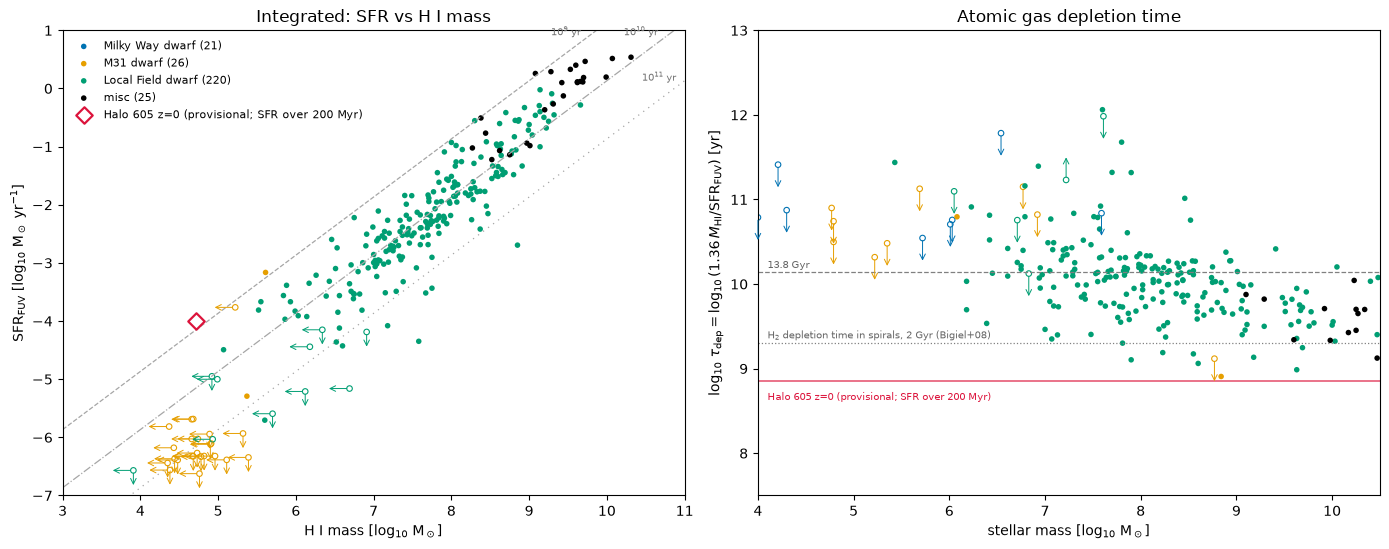

In [11]:
SIM = {  # name: dict(m_hi=Msun, sfr=Msun/yr, m_star=log10 Msun or None)
    "Halo 605 z=0 (provisional; SFR over 200 Myr)": dict(m_hi=5.2e4, sfr=1e-4, m_star=None),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
d = gal.dropna(subset=["log_mhi", "log_sfr_fuv"])

ax = axes[0]                                                    # integrated SFR vs H I mass
x = np.linspace(3, 11, 20)
for t, ls in ((1e9, "--"), (1e10, "-."), (1e11, (0, (1, 4)))):
    ax.plot(x, np.log10(HELIUM) + x - np.log10(t), c="0.65", lw=0.9, ls=ls)
    xl = min(10.9, 0.8 - np.log10(HELIUM) + np.log10(t))                    # stay below the top edge
    ax.text(xl, np.log10(HELIUM) + xl - np.log10(t) + 0.1, rf"$10^{{{int(np.log10(t))}}}$ yr",
            fontsize=7, color="0.45", ha="right")
for g, col in COLOUR.items():
    s = d[d["group"] == g]
    if s.empty:
        continue
    det = s[~s["sfr_fuv_ul"] & ~s["hi_ul"]]
    ax.scatter(det["log_mhi"], det["log_sfr_fuv"], s=16, c=col, edgecolors="none", label=f"{g} ({len(s)})")
    draw_limits(ax, s, "log_mhi", "log_sfr_fuv", "hi_ul", "sfr_fuv_ul", col)
for name, p in SIM.items():
    ax.scatter(np.log10(p["m_hi"]), np.log10(p["sfr"]), marker="D", s=70, c="white", edgecolors="crimson",
               lw=1.6, zorder=6, label=name)
ax.set(xlim=(3, 11), ylim=(-7, 1), xlabel=r"H I mass [log$_{10}$ M$_\odot$]",
       ylabel=r"SFR$_{\rm FUV}$ [log$_{10}$ M$_\odot$ yr$^{-1}$]", title="Integrated: SFR vs H I mass")
ax.legend(fontsize=8, loc="upper left", frameon=False)

ax = axes[1]                                                    # depletion time vs stellar mass
d = d[~(d["sfr_fuv_ul"] & d["hi_ul"])].dropna(subset=["mass_stellar"])
for g, col in COLOUR.items():
    s = d[d["group"] == g]
    det = s[~s["sfr_fuv_ul"] & ~s["hi_ul"]]
    ax.scatter(det["mass_stellar"], det["log_tdep_fuv"], s=16, c=col, edgecolors="none")
    lim = s[s["sfr_fuv_ul"] | s["hi_ul"]]
    ax.scatter(lim["mass_stellar"], lim["log_tdep_fuv"], s=16, facecolors="none", edgecolors=col, lw=0.8)
    for _, r in lim.iterrows():
        dy = 0.3 if r["sfr_fuv_ul"] else -0.3
        ax.annotate("", (r["mass_stellar"], r["log_tdep_fuv"] + dy), (r["mass_stellar"], r["log_tdep_fuv"]),
                    arrowprops=dict(arrowstyle="->", color=col, lw=0.7))
ax.axhline(np.log10(13.8e9), c="0.5", ls="--", lw=0.9)
ax.text(4.1, np.log10(13.8e9) + 0.05, "13.8 Gyr", fontsize=7, color="0.4")
ax.axhline(np.log10(2.0e9), c="0.5", ls=":", lw=0.9)
ax.text(4.1, np.log10(2.0e9) + 0.05, r"H$_2$ depletion time in spirals, 2 Gyr (Bigiel+08)", fontsize=7, color="0.4")
for name, p in SIM.items():
    tdep = np.log10(HELIUM * p["m_hi"] / p["sfr"])
    if p["m_star"] is None:
        ax.axhline(tdep, c="crimson", lw=1.2, alpha=0.7)
        ax.text(4.1, tdep - 0.22, name, fontsize=7, color="crimson")
    else:
        ax.scatter(p["m_star"], tdep, marker="D", s=70, c="white", edgecolors="crimson", lw=1.6, zorder=6)
ax.set(xlim=(4, 10.5), ylim=(7.5, 13), xlabel=r"stellar mass [log$_{10}$ M$_\odot$]",
       ylabel=r"$\log_{10}\,\tau_{\rm dep} = \log_{10}(1.36\,M_{\rm HI}/{\rm SFR_{FUV}})$ [yr]",
       title="Atomic gas depletion time")
fig.tight_layout()
plt.show()

## 7. Open items

- **Halo 605 on the KS plane** needs its H I mass and SFR inside an aperture defined like $R_{26}$ (a
  surface-brightness isophote), and SFRs over ~10 and ~100 Myr to match H$\alpha$ and FUV.
- **Total gas.** Adding H$_2$ needs CO (or a dust-based estimate) for these dwarfs; at these metallicities
  that is the $\alpha_{\rm CO}$ question.
- **Resolved KS.** Bigiel et al. (2008, 2010) measure the relation pixel by pixel at sub-kpc scales; global
  values like these are one point per galaxy and can't show the threshold behaviour seen inside discs.

References: Karachentsev et al. 2013 (AJ 145, 101); Karachentsev & Kaisina 2013 (AJ 146, 46);
Kennicutt 1998 (ApJ 498, 541); Tillaboev et al. 2025; Bigiel et al. 2008 (AJ 136, 2846); Bigiel et al. 2010 (AJ 140, 1194);
Schruba et al. 2011 (AJ 142, 37); Pace et al. (LVDB).